# La escalera de LGD: MCO, logit fraccional, beta, hurdle, boosting y Tobit

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (la LGD de recuperación y el proxy de C08)
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este cuaderno puedes:

- escribir la especificación de cada peldaño de la escalera de C08 (MCO, logit fraccional, beta, hurdle, gradient boosting, Tobit) y decir qué significa su predicción;
- reconstruir un peldaño ajustado a partir de los coeficientes versionados en el artefacto y predecir con `predict_lgd` del motor, de modo que un modelo versionado se pueda reutilizar y comprobar;
- reajustar los cinco peldaños del motor con `fit_ols`, `fit_fractional_logit`, `fit_beta`, `fit_hurdle` y `fit_tobit` sobre una muestra de verdad conocida, y leer qué recupera cada uno;
- explicar por qué el peldaño beta depende de un ajuste de extremos, y leer la sensibilidad versionada a él;
- comparar los peldaños fuera de tiempo en las seis cohortes de incumplimiento de C08, por R cuadrado, correlación de rangos y brecha de calibración, y decir qué muestra la brecha de calibración que no muestra el R cuadrado.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import lgd_models as lm

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Siete artefactos versionados del caso C08, la pérdida dado el incumplimiento de préstamos a pequeñas empresas. Uno es el artefacto de modelos `models-dc-2007-08.json`, que guarda la escalera ajustada (los coeficientes, la estandarización, los parámetros). Los otros seis son las variantes `dc-2003-06.json` a `dc-2020-23.json`, una por cohorte de incumplimiento, que guardan los resultados fuera de tiempo de cada peldaño: R cuadrado, correlación de rangos, la brecha de calibración, la calibración por tramo y las filas de pruebas del motor.

El diseño sigue las reglas de fuga de la investigación. La escalera se ajusta una vez, sobre los incumplimientos cuyo castigo cerró estrictamente antes del corte del 31 de diciembre de 2006, y cada cohorte desde 2007 es una prueba que el ajuste nunca vio. El objetivo es el proxy de castigos del cuaderno 01, así que todo lo que sigue es una afirmación sobre el proxy y no sobre una LGD de recuperación. Los artefactos fueron horneados con un motor anterior al instalado, y la celda siguiente imprime ambas versiones.

In [2]:
# Abrir el artefacto de modelos y las seis variantes por cohorte, e imprimir las versiones que los hornearon
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C08"
models = json.loads((DERIVED / "models-dc-2007-08.json").read_text(encoding="utf-8"))
COHORTS = ["2003-06", "2007-08", "2009-10", "2011-13", "2014-19", "2020-23"]
cohort = {c: json.loads((DERIVED / f"dc-{c}.json").read_text(encoding="utf-8")) for c in COHORTS}
fit = models["fit"]
print("artefacto de modelos horneado con riskvalidation:", models["provenance"]["riskvalidation_version"], "| instalado:", rv.__version__)
print("variantes por cohorte horneadas con:", sorted({v["provenance"]["riskvalidation_version"] for v in cohort.values()}))
print("corte de entrenamiento:", fit["training"]["cutoff_date"], "| incumplimientos ajustados:", f"{fit['training']['n_defaults']:,}")
for model in models["model"]:
    d = model["details"]
    print(f"- {model['id']:21s} {model['title']['es']:48s} biblioteca: {model['engine']} {model['engine_version']}")

artefacto de modelos horneado con riskvalidation: 1.0.1 | instalado: 1.0.1
variantes por cohorte horneadas con: ['1.0.1']
corte de entrenamiento: 2006-12-31 | incumplimientos ajustados: 48,833
- L1-ols                MCO, recortado a [0, 1]                          biblioteca: riskvalidation 1.0.1
- L2-fractional-logit   Logit fraccional (cuasi-verosimilitud)           biblioteca: riskvalidation 1.0.1
- L3-beta               Regresión beta sobre la LGD con extremos ajustados biblioteca: riskvalidation 1.0.1
- L4-hurdle             Dos etapas (hay pérdida o no, luego severidad)   biblioteca: riskvalidation 1.0.1
- L5-gradient-boosted   Árboles con gradiente (catboost, entropía cruzada) biblioteca: catboost 1.2.10
- L6-tobit              Tobit de dos límites                             biblioteca: riskvalidation 1.0.1


## Método

### Paso 1: los seis peldaños y qué predice cada uno

Los seis peldaños predicen la LGD media de un préstamo dadas sus covariables $x$ (el logaritmo del monto y del plazo, las partes garantizada y de madurez, una marca de línea rotativa y las variables indicadoras de sector), con una columna de intercepto. El módulo `lgd_models` del motor implementa cinco de ellos en NumPy y SciPy puros; el sexto es el retador de gradient boosting del pipeline.

| Peldaño | Especificación | Predicción |
|---|---|---|
| L1 MCO | $y = x'\beta + \varepsilon$ | $\hat y = \min(\max(x'\beta, 0), 1)$, recortada solo al predecir |
| L2 logit fraccional | $E[y \mid x] = 1 / (1 + e^{-x'\beta})$, cuasi-verosimilitud de Bernoulli (Papke y Wooldridge 1996) | $\hat y = 1 / (1 + e^{-x'\beta})$ |
| L3 beta | $y \sim \mathrm{Beta}(\mu\varphi, (1-\mu)\varphi)$, $\mu = 1 / (1 + e^{-x'\beta})$, $\mathrm{Var}(y) = \mu(1-\mu)/(1+\varphi)$ (Ferrari y Cribari-Neto 2004), ajustada sobre $\min(\max(y, \epsilon), 1-\epsilon)$ | $\hat y = \mu$ |
| L4 hurdle | etapa 1: $P(y>0 \mid x) = 1/(1+e^{-x'\gamma})$; etapa 2: $E[y \mid y>0, x] = 1/(1+e^{-x'\delta})$ entre los préstamos con $y > 0$ (Leow y Mues 2012; Tong, Mues y Thomas 2013) | $\hat y = P(y>0 \mid x)\,E[y \mid y>0, x]$ |
| L5 gradient boosting | CatBoost con la pérdida de entropía cruzada, 200 árboles de profundidad 6 | la salida del modelo, en [0, 1] |
| L6 Tobit | $y = \min(1, \max(0, y^*))$, $y^* = x'\beta + \varepsilon$, $\varepsilon \sim N(0, \sigma^2)$ (Tobin 1958) | $E[y \mid x]$ de la normal censurada, en forma cerrada |

(Fuentes: los docstrings de `riskvalidation.lgd_ead.lgd_models` en la versión 0.8.1, que nombran a los autores de arriba; los parámetros del gradient boosting se leen del artefacto en el paso 2.) Dos propiedades importan para lo que sigue. MCO puede predecir fuera de [0, 1], así que su predicción se recorta, lo que es una decisión del motor. El peldaño beta no puede tomar exactamente los valores 0 y 1, así que necesita el ajuste de extremos $\epsilon$ del paso 4. La celda de abajo lista los peldaños del artefacto.

In [3]:
# Listar los peldaños del artefacto con su tipo y biblioteca, y los parámetros del peldaño boosted
for rung in fit["ladder"]:
    print(f"{rung['rung_id']:21s} tipo: {rung['kind']:17s} biblioteca: {rung['library']} {rung['library_version']} | covariables: {len(rung['covariates'])} | coeficientes: {len(rung['coefficients'])}")
boosted = next(m for m in models["model"] if m["id"] == "L5-gradient-boosted")["details"]
print("parámetros de L5:", boosted["settings"])
top = sorted(boosted["feature_importance"].items(), key=lambda kv: -kv[1])[:5]
print("cinco variables más importantes de L5:", [(k, round(v, 1)) for k, v in top])

L1-ols                tipo: ols               biblioteca: riskvalidation 1.0.1 | covariables: 16 | coeficientes: 17
L2-fractional-logit   tipo: fractional-logit  biblioteca: riskvalidation 1.0.1 | covariables: 16 | coeficientes: 17
L3-beta               tipo: beta              biblioteca: riskvalidation 1.0.1 | covariables: 16 | coeficientes: 17
L4-hurdle             tipo: hurdle            biblioteca: riskvalidation 1.0.1 | covariables: 16 | coeficientes: 17
L5-gradient-boosted   tipo: gradient-boosted  biblioteca: catboost 1.2.10 | covariables: 16 | coeficientes: 0
L6-tobit              tipo: tobit             biblioteca: riskvalidation 1.0.1 | covariables: 16 | coeficientes: 17
parámetros de L5: {'iterations': 200, 'depth': 6, 'learning_rate': 0.1, 'l2_leaf_reg': 3.0, 'loss_function': 'CrossEntropy', 'thread_count': 1}
cinco variables más importantes de L5: [('seasoning_share', 29.4), ('log_term', 23.1), ('log_amount', 17.6), ('guaranteed_share', 16.5), ('revolver', 9.9)]


### Paso 2: los coeficientes versionados

Un peldaño lineal son sus coeficientes más la estandarización de sus cuatro covariables continuas (cada una se centra y escala con la media y la desviación estándar de la porción de entrenamiento, de modo que los coeficientes sean comparables). El artefacto guarda ambos. La celda imprime los coeficientes del logit fraccional junto a los de MCO, y la estandarización. Un coeficiente sobre una covariable estandarizada es el cambio del predictor lineal por desviación estándar; la marca de línea rotativa y las variables de sector entran como 0 o 1.

In [4]:
# Imprimir los coeficientes de MCO y del logit fraccional lado a lado, y la estandarización de las covariables continuas
ladder = {r["rung_id"]: r for r in fit["ladder"]}
detail = {m["id"]: m["details"] for m in models["model"]}
ols_c = {c["name"]: c["estimate"] for c in ladder["L1-ols"]["coefficients"]}
flogit_c = {c["name"]: c["estimate"] for c in ladder["L2-fractional-logit"]["coefficients"]}
print(f"{'término':44s} {'L1 MCO':>10s} {'L2 logit fraccional':>24s}")
for term in ols_c:
    print(f"{term:44s} {ols_c[term]:10.4f} {flogit_c[term]:24.4f}")
print()
standard = detail["L2-fractional-logit"]["standardisation"]
for name, s in standard.items():
    print(f"estandarización de {name:18s} media {s['mean']:8.4f}  desviación estándar {s['std']:7.4f}")
print("incumplimientos ajustados:", f"{detail['L2-fractional-logit']['n_fitted']:,}", "| excluidos por un proxy fuera de [0, 1], contados y nunca recortados:", f"{detail['L2-fractional-logit']['n_out_of_range_left_out']:,}")

término                                          L1 MCO      L2 logit fraccional
const                                            0.6310                   0.5739
log_amount                                      -0.0742                  -0.3781
log_term                                        -0.0132                  -0.0459
guaranteed_share                                -0.0349                  -0.1798
seasoning_share                                 -0.0789                  -0.3748
revolver                                         0.1040                   0.7434
sector_agriculture                              -0.0388                  -0.1261
sector_mining-utilities-construction             0.0149                   0.0698
sector_manufacturing                             0.0339                   0.1756
sector_wholesale                                 0.0370                   0.1918
sector_retail                                    0.0168                   0.0802
sector_transport            

### Paso 3: predecir con el motor desde los coeficientes versionados

`LgdFit` del motor guarda exactamente lo que almacena el artefacto, así que un peldaño versionado se puede reconstruir y usar: `LgdFit(kind, names, coefficients, extras)`. Los extras son la precisión $\varphi$ y el extremo $\epsilon$ de la beta, los dos vectores de coeficientes del hurdle, y la $\sigma$ del Tobit. `predict_lgd(fit, X)` devuelve entonces la predicción, con solo la de MCO recortada.

La celda siguiente construye la matriz de diseño de tres préstamos inventados (una pequeña línea rotativa de comercio, un préstamo mediano de manufactura, un préstamo agrícola grande a largo plazo) aplicando la estandarización versionada, reconstruye cinco peldaños e imprime sus predicciones, seguidas de las dos etapas del peldaño hurdle. Los valores de las covariables son inventados para ilustrar la aritmética; no son préstamos del archivo.

In [5]:
# Construir la matriz de diseño de tres préstamos inventados, reconstruir cinco peldaños versionados como objetos LgdFit y predecir
covariates = ladder["L2-fractional-logit"]["covariates"]
invented = [  # monto, plazo en meses, parte garantizada, parte de madurez, rotativa, sector
    ("pequeña línea rotativa, comercio", 50_000, 24, 0.50, 0.30, 1, "retail"),
    ("préstamo a plazo mediano, manufactura", 350_000, 84, 0.75, 1.00, 0, "manufacturing"),
    ("préstamo grande a largo plazo, agricultura", 1_500_000, 240, 0.75, 1.00, 0, "agriculture"),
]
rows = []
for _, amount, term, guaranteed, seasoning, revolver, sector in invented:
    raw = {"log_amount": np.log(amount), "log_term": np.log(term), "guaranteed_share": guaranteed, "seasoning_share": seasoning}
    row = [1.0]
    for name in covariates:
        if name in raw:
            row.append((raw[name] - standard[name]["mean"]) / standard[name]["std"])
        elif name == "revolver":
            row.append(float(revolver))
        else:
            row.append(1.0 if name == f"sector_{sector}" else 0.0)
    rows.append(row)
X = np.array(rows)
names = ("const", *covariates)
vec = lambda rung_id: np.array([c["estimate"] for c in ladder[rung_id]["coefficients"]])
hurdle = detail["L4-hurdle"]
rebuilt = {
    "L1 MCO": lm.LgdFit("ols", names, vec("L1-ols")),
    "L2 logit fraccional": lm.LgdFit("fractional-logit", names, vec("L2-fractional-logit")),
    "L3 beta": lm.LgdFit("beta", names, vec("L3-beta"), {"phi": detail["L3-beta"]["phi"], "epsilon": ladder["L3-beta"]["epsilon"]}),
    "L4 hurdle": lm.LgdFit("hurdle", names, vec("L4-hurdle"), {"stage1_coefficients": np.array(hurdle["stage1_coefficients"]), "severity_columns": tuple(hurdle["severity_columns"])}),
    "L6 Tobit": lm.LgdFit("tobit", names, vec("L6-tobit"), {"sigma": detail["L6-tobit"]["sigma"]}),
}
print(f"{'':40s} " + " ".join(f"{label:>10s}" for label in ("préstamo 1", "préstamo 2", "préstamo 3")))
for label, f in rebuilt.items():
    print(f"{label:40s} " + " ".join(f"{p:10.4f}" for p in lm.predict_lgd(f, X)))
stage1 = 1 / (1 + np.exp(-(X @ np.array(hurdle["stage1_coefficients"]))))
stage2 = 1 / (1 + np.exp(-(X @ vec("L4-hurdle"))))
print(f"{'hurdle etapa 1: P(y > 0)':40s} " + " ".join(f"{p:10.4f}" for p in stage1))
print(f"{'hurdle etapa 2: E[y | y > 0]':40s} " + " ".join(f"{p:10.4f}" for p in stage2))
print(f"{'etapa 1 por etapa 2':40s} " + " ".join(f"{p:10.4f}" for p in stage1 * stage2))

                                         préstamo 1 préstamo 2 préstamo 3
L1 MCO                                       0.9467     0.5396     0.3590
L2 logit fraccional                          0.9127     0.5328     0.3326
L3 beta                                      0.9057     0.5363     0.3424
L4 hurdle                                    0.9126     0.5332     0.3287
L6 Tobit                                     0.8972     0.5369     0.3596
hurdle etapa 1: P(y > 0)                     1.0000     0.9948     0.9768
hurdle etapa 2: E[y | y > 0]                 0.9127     0.5360     0.3365
etapa 1 por etapa 2                          0.9126     0.5332     0.3287


Los cinco peldaños coinciden en el orden de los tres préstamos, y difieren más en el primero, que está cerca del tope del rango. Ahí importa la elección del vínculo: MCO da 0.9467 y la esperanza del Tobit 0.8972, con las formas logísticas entre ambos. Las tres últimas filas reproducen a mano la predicción hurdle del motor desde sus dos etapas; la etapa 1 está casi en 1, es decir, cuando casi todo incumplimiento pierde algo la etapa "hay pérdida o no" aporta poca información y el hurdle queda cerca del logit fraccional.

### Paso 4: el ajuste de extremos del peldaño beta

La densidad beta es cero o infinita en 0 y 1, así que el peldaño beta se ajusta sobre $y_\epsilon = \min(\max(y, \epsilon), 1-\epsilon)$, que calcula `endpoint_transform(y, epsilon)`. Qi y Zhao (2011), como registra el docstring del motor, encontraron que los resultados de la beta son muy sensibles a este número pequeño, y C08 informa la sensibilidad en vez de esconderla: `outputs.endpoint_sensitivity` guarda, para tres valores de $\epsilon$, la predicción media y el RMSE en la cohorte. La celda aplica la transformación a cinco valores e imprime la sensibilidad versionada, con los valores de $\varphi$ que el artefacto informa para los tres reajustes.

In [6]:
# Aplicar la transformación de extremos a cinco valores e imprimir la sensibilidad versionada a epsilon
sample = np.array([0.0, 0.2, 0.5, 0.97, 1.0])
for eps in (0.0001, 0.001, 0.01):
    print(f"epsilon={eps:<7}", lm.endpoint_transform(sample, eps))
print()
sens = cohort["2007-08"]["outputs"]["endpoint_sensitivity"]
print(f"{'epsilon':>8s} {'predicción media':>26s} {'RMSE':>8s}")
for row in sens:
    print(f"{row['epsilon']:8.4f} {row['mean_predicted']['value']:26.4f} {row['rmse']:8.4f}")
print("precisión phi de la beta del ajuste versionado (epsilon 0.001):", round(detail["L3-beta"]["phi"], 4))

epsilon=0.0001  [1.000e-04 2.000e-01 5.000e-01 9.700e-01 9.999e-01]
epsilon=0.001   [0.001 0.2   0.5   0.97  0.999]
epsilon=0.01    [0.01 0.2  0.5  0.97 0.99]

 epsilon           predicción media     RMSE
  0.0001                     0.7568   0.2928
  0.0010                     0.7503   0.2942
  0.0100                     0.7402   0.2970
precisión phi de la beta del ajuste versionado (epsilon 0.001): 2.7105


La predicción media del peldaño beta se mueve con $\epsilon$ mientras el RMSE casi no lo hace: quien elige $\epsilon$ por el mejor RMSE también elige un nivel. Un validador debe pedir la sensibilidad y la brecha de calibración en el valor elegido, que es lo que miran los pasos 7 y 8.

### Paso 5: reajustar los peldaños del motor sobre una muestra de verdad conocida

El artefacto versionado guarda los coeficientes ajustados pero no los 47.726 préstamos de entrenamiento (el archivo SBA es un conjunto de terceros que no se versiona), así que los ajustes no se pueden repetir aquí sobre los datos reales. Para ver trabajar las funciones `fit_*` del motor, la celda siguiente genera una muestra pequeña en el cuaderno, **un juguete con verdad conocida, no un caso**: 4.000 préstamos, dos covariables, un cuerpo de pérdidas con distribución beta, 18% de curas exactamente en 0 y 8% de pérdidas totales exactamente en 1. No se lee ningún archivo y no se escribe nada; la semilla es fija. Luego ajusta los cinco peldaños del motor sobre el mismo diseño e informa la predicción media, el RMSE contra el valor realizado y la parte de las predicciones dentro de [0, 1].

Qué mirar: la media de la LGD realizada es el nivel objetivo, y un peldaño bien calibrado lo reproduce. MCO con intercepto y la cuasi-verosimilitud logística lo hacen por sus propias ecuaciones de estimación; los otros peldaños no tienen por qué, y el peldaño beta se ajusta sobre los valores con extremos corregidos.

In [7]:
# Generar una muestra de juguete con verdad conocida, ajustar los cinco peldaños del motor sobre ella y comparar su calibración
rng = np.random.default_rng(20261021)
n = 4000
x1, x2 = rng.normal(size=n), rng.normal(size=n)
Xt = np.column_stack([np.ones(n), x1, x2])
mu = 1 / (1 + np.exp(-(0.4 + 0.8 * x1 - 0.5 * x2)))
body = rng.beta(mu * 4.0, (1 - mu) * 4.0)
y = np.where(rng.random(n) < 0.18, 0.0, np.where(rng.random(n) < 0.08 / 0.82, 1.0, body))
print(f"muestra de juguete: n={n} | parte en 0={np.mean(y == 0):.3f} | parte en 1={np.mean(y == 1):.3f} | LGD realizada media={y.mean():.4f}")

toy = {
    "L1 MCO": lm.fit_ols(Xt, y),
    "L2 logit fraccional": lm.fit_fractional_logit(Xt, y),
    "L3 beta (epsilon 0.001)": lm.fit_beta(Xt, y, 0.001),
    "L4 hurdle": lm.fit_hurdle(Xt, y),
    "L6 Tobit": lm.fit_tobit(Xt, y),
}
print(f"{'':40s} {'predicción media':>24s} {'RMSE':>8s} {'R cuadrado':>12s}")
for label, f in toy.items():
    p = lm.predict_lgd(f, Xt)
    r2 = 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)
    print(f"{label:40s} {p.mean():24.4f} {np.sqrt(np.mean((y - p) ** 2)):8.4f} {r2:12.4f}")
print("beta: precisión phi:", round(toy["L3 beta (epsilon 0.001)"].extras["phi"], 4), "| Tobit sigma:", round(toy["L6 Tobit"].extras["sigma"], 4))

muestra de juguete: n=4000 | parte en 0=0.167 | parte en 1=0.083 | LGD realizada media=0.5217
                                                 predicción media     RMSE   R cuadrado
L1 MCO                                                     0.5217   0.3272       0.1480
L2 logit fraccional                                        0.5217   0.3270       0.1486
L3 beta (epsilon 0.001)                                    0.4881   0.3342       0.1109
L4 hurdle                                                  0.5219   0.3272       0.1479
L6 Tobit                                                   0.5033   0.3291       0.1379
beta: precisión phi: 0.8141 | Tobit sigma: 0.4205


MCO, el logit fraccional y el hurdle empatan en R cuadrado (0.1479 a 0.1486) y en predicción media (0.5217 a 0.5219, la media realizada), mientras que el peldaño beta (0.4881) y la esperanza del Tobit (0.5033) fallan el nivel: la misma lección que en C08, en un entorno donde la verdad es conocida. Ahora la sensibilidad del peldaño beta a $\epsilon$ sobre este juguete, reajustando tres veces, y la descomposición por curas de la investigación, $E[LGD] = P_{cura}\,LGD_{cura} + (1 - P_{cura})\,LGD_{liq}$, que calcula `cure_decomposition` (la descomposición de los practicantes; el motor marca su única fuente académica como NO VERIFICADA, así que el cuaderno enuncia la identidad y no cita a ningún autor). Las dos celdas de abajo usan la muestra de juguete y probabilidades inventadas.

In [8]:
# Reajustar el peldaño beta con tres valores de epsilon sobre la muestra de juguete, y aplicar la descomposición por curas a datos inventados
print(f"media realizada en el juguete: {y.mean():.4f}")
for eps in (0.0001, 0.001, 0.01):
    f = lm.fit_beta(Xt, y, eps)
    print(f"epsilon={eps:<7} predicción media {lm.predict_lgd(f, Xt).mean():.4f}  phi {f.extras['phi']:.4f}")
p_cure = np.array([0.30, 0.50])
print("descomposición por curas para P_cura = 0.30 y 0.50 (LGD_cura 0.05 y 0.10, LGD_liq 0.60 y 0.70):", lm.cure_decomposition(p_cure, np.array([0.05, 0.10]), np.array([0.60, 0.70])))

media realizada en el juguete: 0.5217
epsilon=0.0001  predicción media 0.4776  phi 0.6375
epsilon=0.001   predicción media 0.4881  phi 0.8141
epsilon=0.01    predicción media 0.5022  phi 1.1691
descomposición por curas para P_cura = 0.30 y 0.50 (LGD_cura 0.05 y 0.10, LGD_liq 0.60 y 0.70): [0.435 0.4  ]


### Paso 6: fuera de tiempo, en las seis cohortes

De vuelta a la escalera real. Cada variante por cohorte guarda `outputs.rung_comparison`, los puntajes fuera de tiempo de cada peldaño en esa cohorte: R cuadrado, RMSE, MAE, correlación de rangos de Spearman y la brecha de calibración (el proxy realizado medio menos el predicho medio). La celda imprime una tabla por cohorte. Un peldaño que no pudo evaluarse en una cohorte lleva un `reason` en vez de números, y la celda lo imprime. La brecha de calibración es una cifra a la que apuntan la investigación y las pruebas del motor junto al R cuadrado, porque el R cuadrado es bajo para todo modelo de LGD (Loterman et al. 2012, como informa el docstring del motor, encontraron R cuadrado promedio entre 4% y 43%).

In [9]:
# Imprimir R cuadrado, Spearman y la brecha de calibración de cada peldaño en cada una de las seis cohortes, y decir qué peldaño es el mejor según cada criterio
table = {}
for c in COHORTS:
    o = cohort[c]["outputs"]
    print(f"cohorte {c} (n={o['lgd_distribution']['n']:,}, proxy medio {o['lgd_distribution']['mean']['value']:.4f})")
    print(f"  {'':22s} {'R cuadrado':>12s} {'Spearman':>9s} {'brecha de calibración':>26s}")
    for r in o["rung_comparison"]:
        print(f"  {r['rung_id']:22s} {r['r2']:12.4f} {r['spearman']:9.4f} {r['calibration_gap']:26.4f}")
        table[(c, r["rung_id"])] = (r["r2"], r["calibration_gap"])
    missing = [m["id"] for m in cohort[c]["model"] if m["id"] not in {r["rung_id"] for r in o["rung_comparison"]}]
    for rung_id in missing:
        note = next(t["notes"] for t in cohort[c]["tests"] if t["model_id"] == rung_id)
        print(f"  {rung_id:22s} ausente de la comparación; mensaje del motor, citado tal cual y en inglés: {note}")

print()
print(f"{'cohorte':10s} {'mejor R cuadrado':>24s} {'menor brecha absoluta':>34s}")
same = 0
for c in COHORTS:
    in_c = {k[1]: v for k, v in table.items() if k[0] == c}
    best_r2 = max(in_c, key=lambda k: in_c[k][0])
    best_gap = min(in_c, key=lambda k: abs(in_c[k][1]))
    same += best_r2 == best_gap
    print(f"{c:10s} {best_r2:>24s} {best_gap:>34s}")
positive = sum(v[1] > 0 for v in table.values())
print(f"cohortes donde el mejor R cuadrado es también el mejor calibrado: {same} de {len(COHORTS)} | pares peldaño-cohorte con brecha positiva (realizado sobre predicho): {positive} de {len(table)}")

cohorte 2003-06 (n=21,919, proxy medio 0.7081)
                           R cuadrado  Spearman      brecha de calibración
  L1-ols                       0.2165    0.5920                     0.0293
  L2-fractional-logit          0.2143    0.5927                     0.0350
  L3-beta                      0.1990    0.5863                     0.0473
  L4-hurdle                    0.2152    0.5939                     0.0350
  L5-gradient-boosted          0.2497    0.6391                     0.0342
  L6-tobit                     0.2044    0.5925                     0.0453
cohorte 2007-08 (n=25,299, proxy medio 0.8178)
                           R cuadrado  Spearman      brecha de calibración
  L1-ols                       0.1985    0.6305                     0.0491
  L2-fractional-logit          0.2013    0.6301                     0.0530
  L3-beta                      0.1797    0.6363                     0.0675
  L4-hurdle                    0.2015    0.6302                     0.0531
  L5-g

### Paso 7: calibración por tramo y las pruebas del motor

La media puede estar bien mientras la forma está mal, así que cada cohorte guarda también `calibration_by_bucket`: los préstamos de la cohorte se cortan en cinco grupos iguales por LGD predicha, y para cada grupo la media predicha y la media realizada. Un peldaño bien calibrado queda sobre la diagonal. La celda dibuja la cohorte 2007-08 para el peldaño de logit fraccional y el peldaño boosted. Luego imprime las filas de pruebas propias del motor para la cohorte, versionadas en `tests`: `lgd_calibration_by_segment` (una prueba t pareada de la brecha media), `lgd_discrimination` (la correlación de Spearman contra umbrales fijos) y `lgd_calibration_over_time` (la prueba pareada por período, con ajuste de Bonferroni), cada una con su luz y la versión del motor con que se horneó. Las pruebas son las funciones del motor del cuaderno 06; este cuaderno solo lee sus filas.

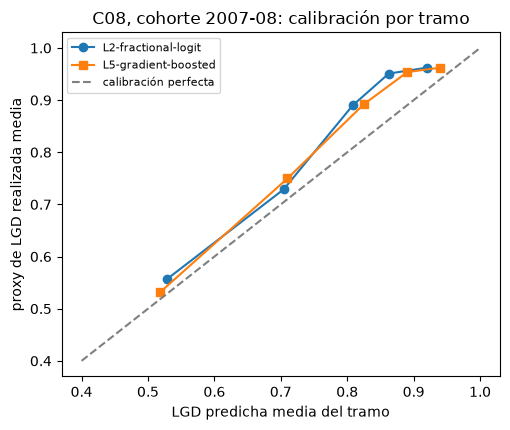

horneado con riskvalidation: 1.0.1
lgd_ead.lgd_calibration_by_segment   L2-fractional-logit   rojo    métrica 0.0530  p 2.78e-188
lgd_ead.lgd_discrimination           L2-fractional-logit   verde   métrica 0.6301  p 0
lgd_ead.lgd_calibration_over_time    L2-fractional-logit   rojo    métrica 0.0748  p 8.61e-147
lgd_ead.lgd_calibration_by_segment   L5-gradient-boosted   rojo    métrica 0.0413  p 8.58e-121
lgd_ead.lgd_discrimination           L5-gradient-boosted   verde   métrica 0.6762  p 0
lgd_ead.lgd_calibration_over_time    L5-gradient-boosted   rojo    métrica 0.0947  p 6.23e-219


In [10]:
# Dibujar la calibración por tramo de dos peldaños e imprimir las filas de pruebas del motor versionadas para la cohorte 2007-08
o = cohort["2007-08"]["outputs"]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
for rung_id, marker in (("L2-fractional-logit", "o"), ("L5-gradient-boosted", "s")):
    rows_b = [b for b in o["calibration_by_bucket"] if b["rung_id"] == rung_id]
    ax.plot([b["predicted"]["value"] for b in rows_b], [b["realised"]["value"] for b in rows_b], marker=marker, label=rung_id)
ax.plot([0.4, 1.0], [0.4, 1.0], color="grey", linestyle="--", label="calibración perfecta")
ax.set_xlabel("LGD predicha media del tramo")
ax.set_ylabel("proxy de LGD realizada media")
ax.set_title("C08, cohorte 2007-08: calibración por tramo")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluado"}
print("horneado con riskvalidation:", cohort["2007-08"]["provenance"]["riskvalidation_version"])
for t in cohort["2007-08"]["tests"]:
    if t["model_id"] in ("L2-fractional-logit", "L5-gradient-boosted") and t["test_id"] != "lgd_ead.downturn_coverage":
        p = "n/a" if t["p_value"] is None else f"{t['p_value']:.3g}"
        print(f"{t['test_id']:36s} {t['model_id']:21s} {LIGHT[t['light']]:7s} métrica {t['metric']:.4f}  p {p}")

## Resultados

- **Un peldaño versionado es un modelo que se puede correr.** Solo con los coeficientes y la estandarización versionados, `LgdFit` y `predict_lgd` dan la LGD del logit fraccional para los tres préstamos inventados: 0,9127, 0,5328 y 0,3326. Las dos etapas del hurdle se multiplican de vuelta en su propia predicción (0,9126, 0,5332 y 0,3287), con la etapa 1 en 1,0000, 0,9948 y 0,9768.
- **Con verdad conocida, el nivel separa los peldaños, no el R cuadrado.** En la muestra de juguete la media realizada es 0,5217. MCO, el logit fraccional y el hurdle la reproducen (0,5217, 0,5217, 0,5219) con R cuadrado entre 0,1479 y 0,1486, mientras que el peldaño beta da 0,4881 y la esperanza del Tobit 0,5033.
- **El peldaño beta depende del ajuste de extremos.** En la cohorte versionada 2007-08 su predicción media es 0,7568, 0,7503 y 0,7402 para $\epsilon$ igual a 0,0001, 0,001 y 0,01, mientras que el RMSE pasa de 0,2928 a 0,2970. En el juguete los mismos tres valores dan 0,4776, 0,4881 y 0,5022 frente a una media realizada de 0,5217.
- **Fuera de tiempo, el R cuadrado es bajo para todos los peldaños, y el mejor R cuadrado no siempre es la mejor calibración.** Sobre los 33 puntajes peldaño-cohorte del paso 6, el R cuadrado va de 0,0975 a 0,2497. El peldaño boosted tiene el mayor R cuadrado en las seis cohortes y la menor brecha de calibración absoluta en solo 2 de las 6. La brecha es positiva, el proxy realizado sobre el predicho, en 32 de los 33 puntajes (la excepción es el logit fraccional en 2011-13, con -0,0031).
- **El peldaño hurdle no corrió en tres cohortes.** En 2009-10, 2011-13 y 2020-23 está ausente de la comparación y sus filas de pruebas son `not_evaluated`, con el mensaje del motor de que el logit fraccional no convergió. El artefacto registra ese mensaje y ninguna otra causa, y fue horneado con el motor 0.6.0, así que de los archivos versionados no se sabe si la 0.8.1 convergería.
- **Las pruebas del motor convierten la brecha en una luz.** En 2007-08 el logit fraccional (brecha 0,0530) y el peldaño boosted (0,0413) están en rojo en calibración y en verde en discriminación (Spearman 0,6301 y 0,6762): el ordenamiento funciona y el nivel es demasiado bajo, para un proxy cuya dirección de sesgo declara el artefacto.

Lo que el cuaderno no hace: no reajusta la escalera sobre los préstamos SBA reales, que no se versionan, y no nombra un mejor peldaño. La muestra de juguete se genera en el cuaderno para mostrar los ajustes y no tiene relación con ningún prestamista.

## Resumen

- Seis peldaños, un objetivo: MCO recortado al predecir, logit fraccional (cuasi-verosimilitud), beta con extremos ajustados, un hurdle de dos etapas, árboles con boosting y Tobit. El motor implementa cinco, y el artefacto versionado guarda sus coeficientes y extras, de modo que cualquiera se puede reconstruir como un `LgdFit` y usar con `predict_lgd`.
- En una muestra de juguete con verdad conocida el R cuadrado de los peldaños es cercano y su calibración no; el peldaño beta se mueve con el ajuste de extremos, que C08 informa como sensibilidad.
- Fuera de tiempo, en las seis cohortes de C08, el R cuadrado es bajo para todos los peldaños y el peldaño con el mayor R cuadrado es el mejor calibrado solo en algunas cohortes, así que la brecha de calibración es un segundo criterio. Las pruebas del motor convierten la brecha en una luz con su valor p y la versión que la horneó.
- Todo aquí trata del proxy de castigos de C08, no de una LGD de recuperación.

**Qué probar a continuación.** Reconstruye el peldaño beta L3 con los otros dos valores de $\epsilon$ informados en `epsilons_reported` del artefacto y compara sus predicciones para los tres préstamos inventados; luego sigue con el cuaderno 04, que pregunta qué hace un ciclo adverso a estas LGD y dónde muerden los pisos regulatorios.

## Referencias

- Papke, L. E. y Wooldridge, J. M. (1996), la cuasi-verosimilitud de Bernoulli para respuestas fraccionales (el logit fraccional), como se nombra en la documentación del motor de `riskvalidation.lgd_ead.lgd_models`.
- Ferrari, S. L. P. y Cribari-Neto, F. (2004), la regresión beta con vínculo logit en la media y vínculo log en la precisión, como se nombra en el mismo docstring.
- Leow, M. y Mues, C. (2012) y Tong, E. N. C., Mues, C. y Thomas, L. C. (2013), el modelo de LGD en dos etapas (hurdle), como se nombran en el docstring de `fit_hurdle`.
- Tobin, J. (1958), la regresión normal censurada, como se nombra en el docstring de `fit_tobit`.
- Loterman, G., Brown, I., Martens, D., Mues, C. y Baesens, B. (2012), Benchmarking regression algorithms for loss given default modeling, International Journal of Forecasting 28(1). https://doi.org/10.1016/j.ijforecast.2011.01.006
- Qi, M. y Zhao, X. (2011), Comparison of modeling methods for loss given default, Journal of Banking and Finance 35(11). https://doi.org/10.1016/j.jbankfin.2011.03.011
- BCBS, Basel Framework, CRE32 (enfoque de calificaciones internas; los pisos de LGD se aplican en el cuaderno 04). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Este repositorio: `docs/design/SDD.md` (caso C08) y `data/derived/C08/` (el artefacto de modelos y las seis variantes por cohorte).